# LLM Inference Lab on Kaggle (T4 x2)

**Goal:** see prefill vs decode, batching, KV cache, quantization and tensor parallelism with your own eyes.

**Before you start (Notebook settings, right sidebar):**
1. *Accelerator* -> **GPU T4 x2** (needs a phone-verified account)
2. *Internet* -> **On** (needed for pip and Hugging Face downloads)
3. Run cells top to bottom. Do not run two GPU notebooks at once (shared weekly quota).

**Structure:** Part 1 environment and server, Part 2 napkin math, Part 3 benchmark client, Part 4 experiments.
The benchmark client talks to any OpenAI-compatible server, so if the install step gives you trouble you can swap the engine without touching the rest.

## Part 1: Environment and server

In [1]:
import subprocess, sys
print(sys.version)
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Mon Oct 19 23:43:09 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

### Install the engine
This is the step most likely to cause trouble on Kaggle: the T4 is an older (Turing, compute capability 7.5) GPU, and vLLM's support for it depends on the version.
Try Option A first. If it fails, paste the error back to me and we will switch to a fallback (llama.cpp with CUDA, or a community T4 build of vLLM that you should read before trusting).

In [2]:
# Option A: upstream vLLM from PyPI. Takes a few minutes and may replace Kaggle's preinstalled torch.
!pip install -q vllm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 5.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 66.0 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.7/211.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 62.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 504.7/504.7 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.4/45.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 77.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 41.2 MB/s eta 0:00:00:00:0100:01


In [3]:
import vllm, torch
print("vllm", vllm.__version__, "| torch", torch.__version__)
print([torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])
print("compute capability:", torch.cuda.get_device_capability(0))

vllm 0.32.0 | torch 2.13.0+cu130
['Tesla T4', 'Tesla T4']
compute capability: (7, 5)


In [9]:
!pip uninstall -y torchaudio

Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128


### Server helpers
We launch the server as a background process and write its log to a file, so the notebook stays usable and we can restart with different settings.

In [10]:
import subprocess, time, os, signal, shlex, sys, requests

PORT = 8000
BASE = f"http://127.0.0.1:{PORT}"
LOG = "/kaggle/working/server.log"
SERVER = {"proc": None}

def tail_log(n=40):
    with open(LOG) as f:
        return "".join(f.readlines()[-n:])

def stop_server():
    p = SERVER["proc"]
    if p and p.poll() is None:
        os.killpg(os.getpgid(p.pid), signal.SIGTERM)
        try:
            p.wait(timeout=30)
        except subprocess.TimeoutExpired:
            os.killpg(os.getpgid(p.pid), signal.SIGKILL)
    SERVER["proc"] = None
    time.sleep(3)

def start_server(model, extra_args="", timeout=900):
    stop_server()
    cmd = (f"{sys.executable} -m vllm.entrypoints.openai.api_server "
           f"--model {model} --port {PORT} --dtype half {extra_args}")
    print("$", cmd)
    logf = open(LOG, "w")
    SERVER["proc"] = subprocess.Popen(shlex.split(cmd), stdout=logf,
                                      stderr=subprocess.STDOUT, preexec_fn=os.setsid)
    t0 = time.time()
    while time.time() - t0 < timeout:
        if SERVER["proc"].poll() is not None:
            print("Server exited. Last log lines:\n", tail_log(40))
            return False
        try:
            if requests.get(f"{BASE}/health", timeout=2).status_code == 200:
                print(f"Ready in {time.time() - t0:.0f}s  <- this is your cold-start time")
                return True
        except requests.RequestException:
            pass
        time.sleep(5)
    print("Timed out. Last log lines:\n", tail_log(40))
    return False

### Start a first server (small model, one GPU)

In [11]:
MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
ok = start_server(MODEL, "--max-model-len 4096 --gpu-memory-utilization 0.85 --max-num-seqs 64 --tensor-parallel-size 1")

$ /usr/bin/python3 -m vllm.entrypoints.openai.api_server --model Qwen/Qwen2.5-1.5B-Instruct --port 8000 --dtype half --max-model-len 4096 --gpu-memory-utilization 0.85 --max-num-seqs 64 --tensor-parallel-size 1
Ready in 160s  <- this is your cold-start time


In [12]:
# Smoke test
r = requests.post(f"{BASE}/v1/chat/completions", json={
    "model": MODEL,
    "messages": [{"role": "user", "content": "Explain what a GPU is in two sentences."}],
    "max_tokens": 80})
print(r.json()["choices"][0]["message"]["content"])
print(r.json()["usage"])

A GPU (Graphics Processing Unit) is a specialized electronic circuit designed to rapidly manipulate and alter memory to accelerate the creation of images in a frame buffer intended for output to a display device. It provides a high degree of parallel processing capability which allows it to perform many calculations simultaneously, making it highly efficient for tasks such as rendering graphics or performing complex mathematical computations.
{'prompt_tokens': 39, 'total_tokens': 111, 'completion_tokens': 72, 'prompt_tokens_details': None, 'completion_tokens_details': None}


In [13]:
# What did the engine decide about memory? Look for the KV cache lines.
print("".join(l for l in open(LOG) if "KV cache" in l or "GiB" in l)[:3000])

(EngineCore pid=311) INFO 10-20 00:04:20 [weight_utils.py:1108] Filesystem type for checkpoints: OVERLAY. Checkpoint size: 2.88 GiB. Available RAM: 3.74 GiB.
(EngineCore pid=311) INFO 10-20 00:04:25 [model_runner.py:424] Model loading took 2.98 GiB memory and 27.841852 seconds
(EngineCore pid=311) INFO 10-20 00:04:25 [utils.py:347] Using LBNHC KV cache layout.
(EngineCore pid=311) INFO 10-20 00:05:01 [model_runner.py:1127] Graph capturing finished in 7 secs, took 0.13 GiB
(EngineCore pid=311) INFO 10-20 00:05:02 [gpu_worker.py:759] Available KV cache memory: 8.67 GiB
(EngineCore pid=311) INFO 10-20 00:05:02 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.8500 is equivalent to --gpu-memory-utilization=0.8405 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.8595. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCor

## Part 2: Napkin math (predict before you measure)
Decode is memory-bound, so the single-user speed ceiling is roughly **memory bandwidth / weight bytes**. The T4 has about 320 GB/s.

In [14]:
from transformers import AutoConfig

def napkin(model, params_b, bytes_per_param=2, bw_gbs=320):
    cfg = AutoConfig.from_pretrained(model)
    head_dim = cfg.hidden_size // cfg.num_attention_heads
    kv_per_token = 2 * cfg.num_hidden_layers * cfg.num_key_value_heads * head_dim * 2  # K+V, fp16
    weights_gb = params_b * bytes_per_param
    print(f"weights                ~ {weights_gb:.1f} GB")
    print(f"KV cache per token     ~ {kv_per_token/1024:.0f} KB")
    print(f"KV for one 4096 ctx    ~ {kv_per_token*4096/1e9:.2f} GB per sequence")
    print(f"decode ceiling (1 user)~ {bw_gbs/weights_gb:.0f} tok/s  (real number will be lower)")

napkin(MODEL, 1.5)

weights                ~ 3.0 GB
KV cache per token     ~ 28 KB
KV for one 4096 ctx    ~ 0.12 GB per sequence
decode ceiling (1 user)~ 107 tok/s  (real number will be lower)


## Part 3: Benchmark client
Streams responses, and measures **TTFT** (time to first token), **inter-token latency**, per-user speed and total throughput.
Each prompt starts with a random tag so the prefix cache cannot hide the real prefill cost.

In [15]:
import asyncio, aiohttp, json, random, string
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

FILLER = ("The quick brown fox jumps over the lazy dog. " * 200).split()

def make_prompt(n_words):
    tag = "".join(random.choices(string.ascii_lowercase, k=8))
    return f"[{tag}] Summarize the following text in detail:\n" + " ".join(FILLER[:n_words])

async def one_request(session, model, prompt, max_tokens):
    payload = {"model": model, "messages": [{"role": "user", "content": prompt}],
               "max_tokens": max_tokens, "temperature": 0.7, "stream": True,
               "ignore_eos": True}  # force full-length outputs for a fair test (vLLM extension)
    t0 = time.perf_counter(); ttft = None; n = 0
    async with session.post(f"{BASE}/v1/chat/completions", json=payload) as resp:
        resp.raise_for_status()
        async for raw in resp.content:
            line = raw.decode().strip()
            if not line.startswith("data:"):
                continue
            data = line[5:].strip()
            if data == "[DONE]":
                break
            chunk = json.loads(data)
            if chunk.get("choices") and chunk["choices"][0]["delta"].get("content"):
                if ttft is None:
                    ttft = time.perf_counter() - t0
                n += 1  # one streamed chunk ~ one token
    return {"ttft": ttft, "e2e": time.perf_counter() - t0, "tokens": n}

async def run_level(model, concurrency, n_requests, prompt_words, max_tokens):
    sem = asyncio.Semaphore(concurrency)
    timeout = aiohttp.ClientTimeout(total=1800)
    async with aiohttp.ClientSession(timeout=timeout, connector=aiohttp.TCPConnector(limit=0)) as s:
        async def task():
            async with sem:
                return await one_request(s, model, make_prompt(prompt_words), max_tokens)
        t0 = time.perf_counter()
        results = await asyncio.gather(*[task() for _ in range(n_requests)])
        wall = time.perf_counter() - t0
    ok = [r for r in results if r["ttft"] is not None and r["tokens"] > 1]
    ttft = np.array([r["ttft"] for r in ok])
    itl = np.array([(r["e2e"] - r["ttft"]) / (r["tokens"] - 1) for r in ok])
    return {"concurrency": concurrency, "requests": len(ok),
            "throughput_tok_s": sum(r["tokens"] for r in ok) / wall,
            "ttft_p50": np.percentile(ttft, 50), "ttft_p95": np.percentile(ttft, 95),
            "itl_ms_p50": np.percentile(itl, 50) * 1000,
            "per_user_tok_s": 1 / itl.mean()}

async def sweep(model, levels=(1, 2, 4, 8, 16, 32), prompt_words=300, max_tokens=128, reqs_per_level=3):
    await run_level(model, 1, 2, prompt_words, 16)  # warm-up
    rows = []
    for c in levels:
        row = await run_level(model, c, max(c * reqs_per_level, 6), prompt_words, max_tokens)
        rows.append(row)
        print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in row.items()})
    return pd.DataFrame(rows)

def plot(dfs):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    for label, df in dfs.items():
        ax[0].plot(df.concurrency, df.throughput_tok_s, marker="o", label=label)
        ax[1].plot(df.concurrency, df.ttft_p95, marker="o", label=label)
        ax[2].plot(df.concurrency, df.per_user_tok_s, marker="o", label=label)
    for a, t, y in zip(ax, ["Total throughput", "p95 time to first token", "Speed seen by each user"],
                       ["tokens/s (all users)", "seconds", "tokens/s (per user)"]):
        a.set_title(t); a.set_ylabel(y); a.set_xlabel("concurrent users")
        a.set_xscale("log", base=2); a.grid(alpha=.3); a.legend()
    plt.tight_layout(); plt.show()

## Part 4: Experiments
For each one, **write down your prediction first**, then run it.

### Experiment 1: the batching curve (baseline)
Prediction: per-user speed drops as users are added, but total throughput climbs a lot. Where does it flatten?

{'concurrency': 1, 'requests': 6, 'throughput_tok_s': 51.6, 'ttft_p50': np.float64(0.09), 'ttft_p95': np.float64(0.1), 'itl_ms_p50': np.float64(18.7), 'per_user_tok_s': np.float64(53.26)}
{'concurrency': 2, 'requests': 6, 'throughput_tok_s': 98.36, 'ttft_p50': np.float64(0.17), 'ttft_p95': np.float64(1.13), 'itl_ms_p50': np.float64(16.7), 'per_user_tok_s': np.float64(59.5)}
{'concurrency': 4, 'requests': 12, 'throughput_tok_s': 152.17, 'ttft_p50': np.float64(0.31), 'ttft_p95': np.float64(2.52), 'itl_ms_p50': np.float64(18.15), 'per_user_tok_s': np.float64(54.66)}
{'concurrency': 8, 'requests': 24, 'throughput_tok_s': 259.31, 'ttft_p50': np.float64(0.54), 'ttft_p95': np.float64(2.82), 'itl_ms_p50': np.float64(21.15), 'per_user_tok_s': np.float64(47.04)}
{'concurrency': 16, 'requests': 48, 'throughput_tok_s': 399.72, 'ttft_p50': np.float64(1.15), 'ttft_p95': np.float64(3.53), 'itl_ms_p50': np.float64(27.09), 'per_user_tok_s': np.float64(36.02)}
{'concurrency': 32, 'requests': 96, 'throug

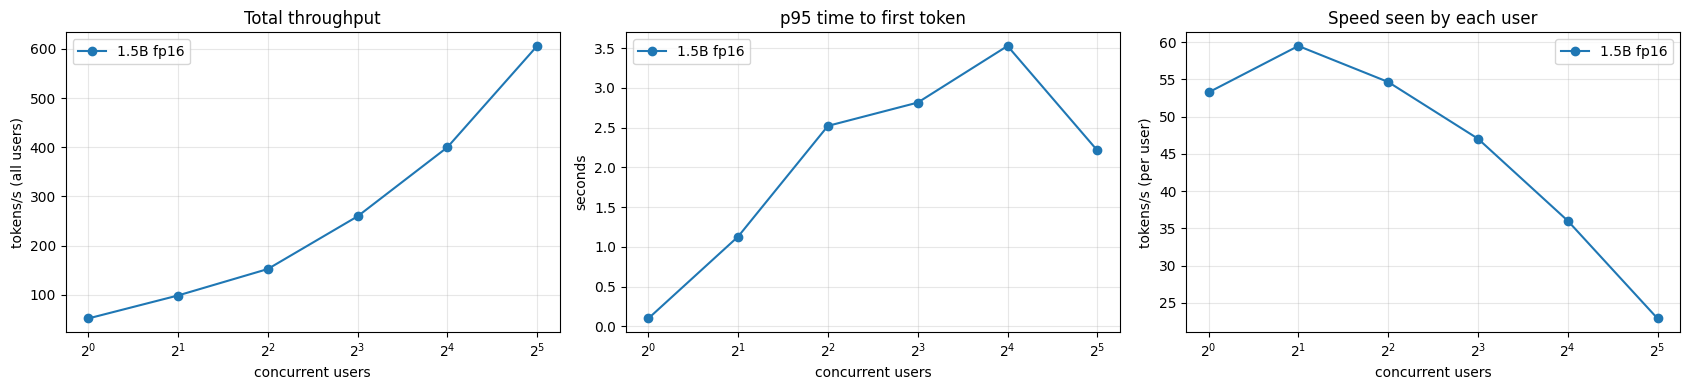

,concurrency,requests,throughput_tok_s,ttft_p50,ttft_p95,itl_ms_p50,per_user_tok_s
0,1,6,51.600291,0.094678,0.100605,18.695895,53.261096
1,2,6,98.364663,0.165416,1.130771,16.697205,59.497988
2,4,12,152.165341,0.310447,2.522869,18.154678,54.663993
3,8,24,259.305544,0.541502,2.816058,21.150442,47.044640
4,16,48,399.719688,1.146707,3.528027,27.089148,36.021049
5,32,96,605.911072,1.168400,2.213973,43.535226,22.894288


In [16]:
results = {}
results["1.5B fp16"] = await sweep(MODEL)
plot(results)
results["1.5B fp16"]

Compare the concurrency-1 per-user speed with the napkin ceiling from Part 2. The gap is kernel, scheduling and sampling overhead.
The "knee" is where p95 TTFT starts rising sharply: that is your sensible max concurrency per replica.

### Look at the engine's own metrics (this is what Prometheus would scrape)

In [17]:
txt = requests.get(f"{BASE}/metrics").text
keys = ("num_requests_running", "num_requests_waiting", "kv_cache_usage", "gpu_cache_usage",
        "preemption", "time_to_first_token_seconds_sum", "time_to_first_token_seconds_count")
for l in txt.splitlines():
    if not l.startswith("#") and any(k in l for k in keys):
        print(l)

vllm:num_requests_running{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:num_requests_waiting{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:num_requests_waiting_by_reason{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct",reason="capacity"} 0.0
vllm:num_requests_waiting_by_reason{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct",reason="deferred"} 0.0
vllm:kv_cache_usage_perc{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:num_preemptions_total{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 0.0
vllm:num_preemptions_created{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 1.7924547293225603e+09
vllm:time_to_first_token_seconds_count{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 195.0
vllm:time_to_first_token_seconds_sum{engine="0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 230.17198252677917
vllm:request_num_preemptions_bucket{engine="0",le="1.0",model_name="Qwen/Qwen2.5-1.5B-Instruct"} 195.0
vllm:request_num_preemptions_bucket{engi

### Experiment 2: prefill vs decode
Prediction: long prompts with tiny outputs stress **compute** (prefill) and hurt TTFT; short prompts with long outputs stress **memory bandwidth** (decode).

In [18]:
rows = []
for words in (50, 400, 1500):
    r = await run_level(MODEL, 4, 12, words, 16)
    r["prompt_words"] = words
    rows.append(r)
pd.DataFrame(rows)[["prompt_words", "ttft_p50", "ttft_p95", "itl_ms_p50"]]

,prompt_words,ttft_p50,ttft_p95,itl_ms_p50
0,50,0.082720,0.123347,16.151428
1,400,0.405041,0.417611,17.290479
2,1500,1.714903,2.405938,84.088996


### Experiment 3: too few batch slots (`--max-num-seqs`)
Prediction: with only 4 slots, extra users wait in a queue, so TTFT explodes at high concurrency while throughput plateaus early.

$ /usr/bin/python3 -m vllm.entrypoints.openai.api_server --model Qwen/Qwen2.5-1.5B-Instruct --port 8000 --dtype half --max-model-len 4096 --gpu-memory-utilization 0.85 --max-num-seqs 4
Ready in 115s  <- this is your cold-start time
{'concurrency': 1, 'requests': 6, 'throughput_tok_s': 45.89, 'ttft_p50': np.float64(0.1), 'ttft_p95': np.float64(0.1), 'itl_ms_p50': np.float64(20.85), 'per_user_tok_s': np.float64(47.22)}
{'concurrency': 2, 'requests': 6, 'throughput_tok_s': 108.29, 'ttft_p50': np.float64(0.14), 'ttft_p95': np.float64(0.18), 'itl_ms_p50': np.float64(17.65), 'per_user_tok_s': np.float64(57.27)}
{'concurrency': 4, 'requests': 12, 'throughput_tok_s': 193.28, 'ttft_p50': np.float64(0.32), 'ttft_p95': np.float64(0.33), 'itl_ms_p50': np.float64(18.24), 'per_user_tok_s': np.float64(53.55)}
{'concurrency': 8, 'requests': 24, 'throughput_tok_s': 194.23, 'ttft_p50': np.float64(2.86), 'ttft_p95': np.float64(2.94), 'itl_ms_p50': np.float64(18.38), 'per_user_tok_s': np.float64(53.51)}
{

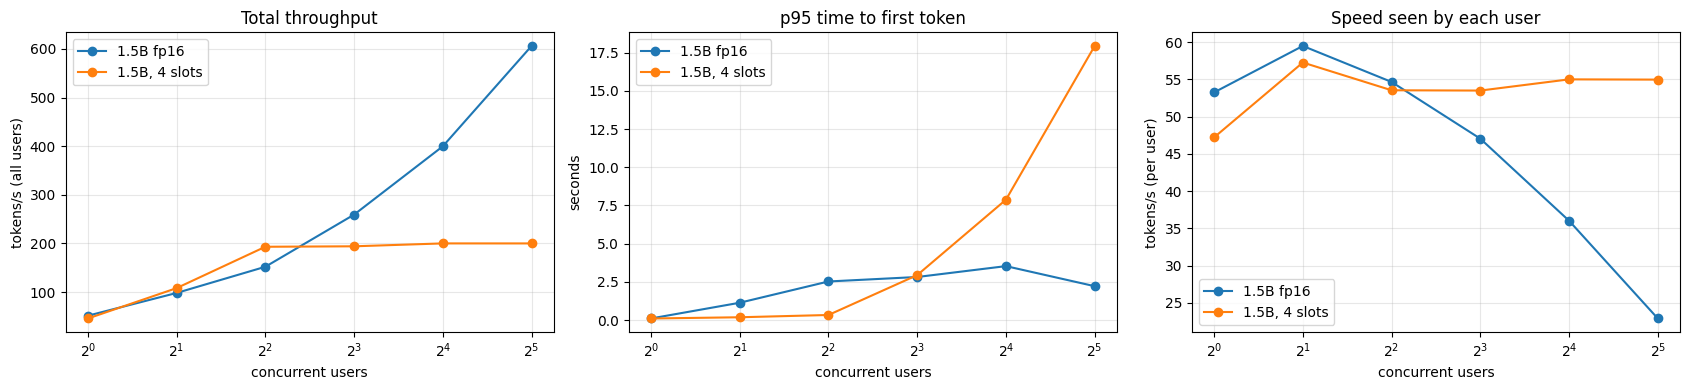

In [19]:
ok = start_server(MODEL, "--max-model-len 4096 --gpu-memory-utilization 0.85 --max-num-seqs 4")
results["1.5B, 4 slots"] = await sweep(MODEL)
plot(results)

### Experiment 4: quantization (bigger model, smaller weights)
A 7B model in fp16 is ~15 GB and will not fit one T4. In 4-bit AWQ it is ~5 GB. Prediction: decode is faster per parameter because fewer bytes cross the memory bus.

$ /usr/bin/python3 -m vllm.entrypoints.openai.api_server --model Qwen/Qwen2.5-7B-Instruct-AWQ --port 8000 --dtype half --quantization awq --max-model-len 4096 --gpu-memory-utilization 0.90 --max-num-seqs 32
Ready in 155s  <- this is your cold-start time


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

weights                ~ 4.2 GB
KV cache per token     ~ 56 KB
KV for one 4096 ctx    ~ 0.23 GB per sequence
decode ceiling (1 user)~ 77 tok/s  (real number will be lower)
{'concurrency': 1, 'requests': 6, 'throughput_tok_s': 32.84, 'ttft_p50': np.float64(0.31), 'ttft_p95': np.float64(0.32), 'itl_ms_p50': np.float64(28.01), 'per_user_tok_s': np.float64(35.43)}
{'concurrency': 2, 'requests': 6, 'throughput_tok_s': 54.44, 'ttft_p50': np.float64(0.64), 'ttft_p95': np.float64(1.28), 'itl_ms_p50': np.float64(31.34), 'per_user_tok_s': np.float64(32.08)}
{'concurrency': 4, 'requests': 12, 'throughput_tok_s': 89.86, 'ttft_p50': np.float64(1.18), 'ttft_p95': np.float64(3.34), 'itl_ms_p50': np.float64(29.88), 'per_user_tok_s': np.float64(32.35)}
{'concurrency': 8, 'requests': 24, 'throughput_tok_s': 143.46, 'ttft_p50': np.float64(2.03), 'ttft_p95': np.float64(4.49), 'itl_ms_p50': np.float64(36.12), 'per_user_tok_s': np.float64(27.8)}
{'concurrency': 16, 'requests': 48, 'throughput_tok_s': 190.56

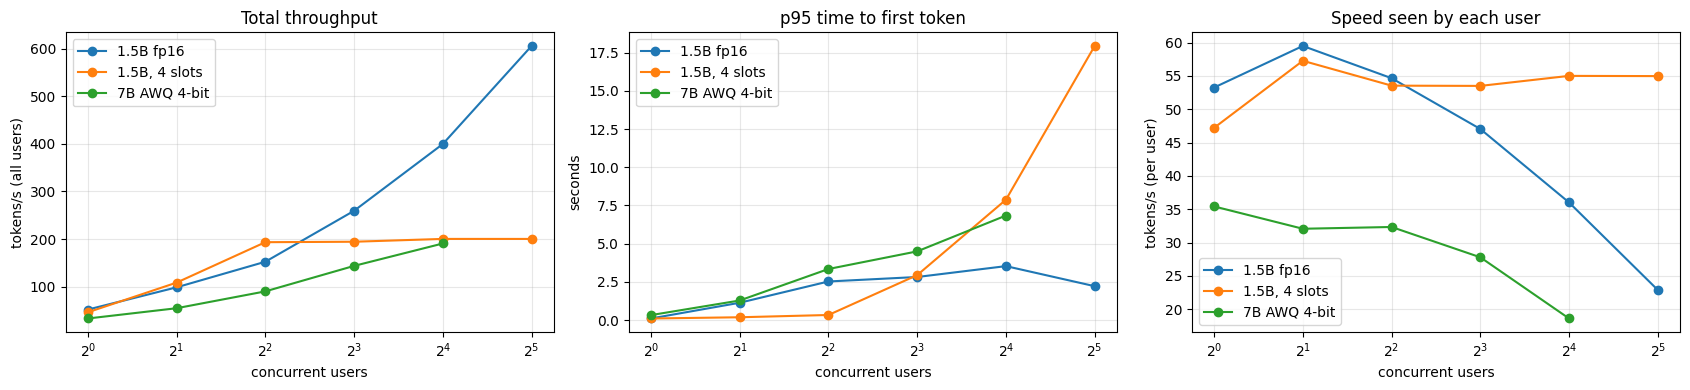

In [20]:
MODEL_7B_AWQ = "Qwen/Qwen2.5-7B-Instruct-AWQ"
ok = start_server(MODEL_7B_AWQ, "--quantization awq --max-model-len 4096 --gpu-memory-utilization 0.90 --max-num-seqs 32")
if ok:
    napkin("Qwen/Qwen2.5-7B-Instruct", 7.6, bytes_per_param=0.55)
    results["7B AWQ 4-bit"] = await sweep(MODEL_7B_AWQ, levels=(1, 2, 4, 8, 16))
    plot(results)

### Experiment 5: tensor parallelism (the model that does not fit one GPU)
Run the 7B in fp16 across both T4s. Prediction: it works, but you pay GPU-to-GPU communication over PCIe on every layer, so it will not be 2x faster than one GPU would be.
Also try TP=2 on the 1.5B model: for tiny models, communication overhead can make TP slower than a single GPU.

$ /usr/bin/python3 -m vllm.entrypoints.openai.api_server --model Qwen/Qwen2.5-7B-Instruct --port 8000 --dtype half --tensor-parallel-size 2 --max-model-len 2048 --gpu-memory-utilization 0.90 --max-num-seqs 16
Ready in 260s  <- this is your cold-start time
{'concurrency': 1, 'requests': 6, 'throughput_tok_s': 10.15, 'ttft_p50': np.float64(0.25), 'ttft_p95': np.float64(0.27), 'itl_ms_p50': np.float64(110.11), 'per_user_tok_s': np.float64(10.24)}
{'concurrency': 2, 'requests': 6, 'throughput_tok_s': 45.87, 'ttft_p50': np.float64(0.35), 'ttft_p95': np.float64(1.54), 'itl_ms_p50': np.float64(37.25), 'per_user_tok_s': np.float64(25.56)}
{'concurrency': 4, 'requests': 12, 'throughput_tok_s': 79.19, 'ttft_p50': np.float64(0.78), 'ttft_p95': np.float64(3.05), 'itl_ms_p50': np.float64(39.12), 'per_user_tok_s': np.float64(24.31)}
{'concurrency': 8, 'requests': 24, 'throughput_tok_s': 138.29, 'ttft_p50': np.float64(1.09), 'ttft_p95': np.float64(3.65), 'itl_ms_p50': np.float64(43.09), 'per_user_tok

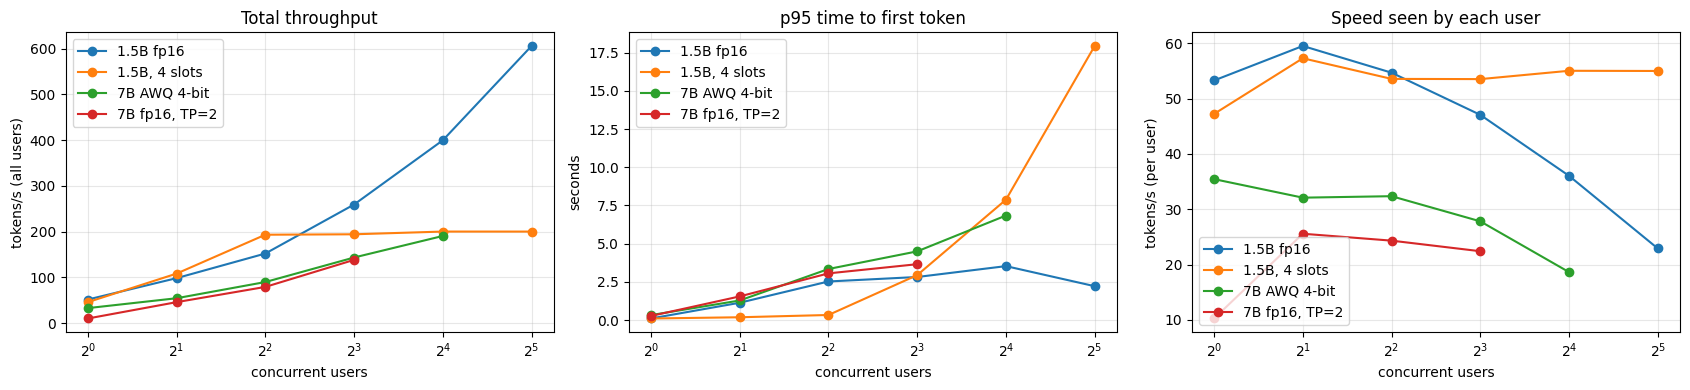

In [21]:
MODEL_7B = "Qwen/Qwen2.5-7B-Instruct"
ok = start_server(MODEL_7B, "--tensor-parallel-size 2 --max-model-len 2048 --gpu-memory-utilization 0.90 --max-num-seqs 16", timeout=1500)
if ok:
    results["7B fp16, TP=2"] = await sweep(MODEL_7B, levels=(1, 2, 4, 8))
    plot(results)

## Cleanup
Stop the server when done so the GPU is released, and shut down the session (the weekly quota keeps counting while it is open).

In [22]:
stop_server()

## Reflection questions
1. At which concurrency did throughput stop improving, and what was happening to p95 TTFT there?
2. How close was concurrency-1 decode speed to the napkin ceiling? What might explain the gap?
3. How much KV cache memory did the engine reserve (see the log), and how many 4096-token sequences does that allow?
4. Why did AWQ make the 7B model usable, and what did you give up?
5. When was TP=2 worth it and when was it not?